<a href="https://colab.research.google.com/github/santana-robledo/Machine-Learning-en-Python/blob/main/Clase_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np

np.random.seed(42)
tamanio_muestra = 1000

generos = np.random.choice(["hombre", "mujer"], size=tamanio_muestra, p=[0.6, 0.4])
razas = np.random.choice(["blanco", "negro"], size=tamanio_muestra, p=[0.7, 0.3])
experiencia = np.random.randint(1, 10, size=tamanio_muestra)

calificacion_historica = []
for g, r, exp in zip(generos, razas, experiencia):
    base = 50 + (exp * 5)
    if g == "hombre":
        base += 15
    if r == "blanco":
        base += 10
    puntaje = min(max(base + np.random.normal(0, 5), 0), 100)
    calificacion_historica.append(puntaje)

datos_reclutamiento = pd.DataFrame({
    "genero": generos,
    "raza": razas,
    "experiencia_anios": experiencia,
    "puntaje_modelo": calificacion_historica,
    "contratado": [1 if p > 70 else 0 for p in calificacion_historica]
})

print(datos_reclutamiento.head())

   genero    raza  experiencia_anios  puntaje_modelo  contratado
0  hombre  blanco                  7      100.000000           1
1   mujer  blanco                  3       71.191770           1
2   mujer   negro                  7       84.091124           1
3  hombre   negro                  8      100.000000           1
4  hombre   negro                  6       99.395882           1


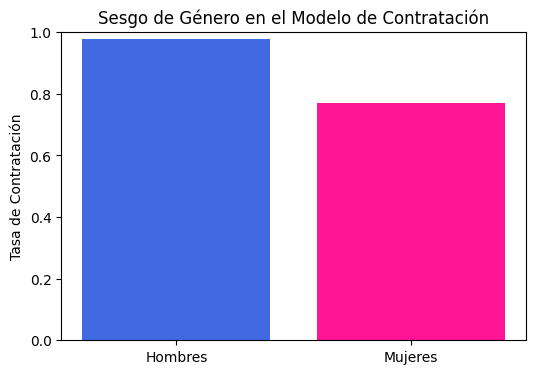

In [2]:
import matplotlib.pyplot as plt

tasa_hombres = datos_reclutamiento[datos_reclutamiento["genero"] == "hombre"]["contratado"].mean()
tasa_mujeres = datos_reclutamiento[datos_reclutamiento["genero"] == "mujer"]["contratado"].mean()

grupos_genero = ["Hombres", "Mujeres"]
tasas_genero = [tasa_hombres, tasa_mujeres]

plt.figure(figsize=(6, 4))
plt.bar(grupos_genero, tasas_genero, color=["royalblue", "deeppink"])
plt.ylabel("Tasa de Contratación")
plt.title("Sesgo de Género en el Modelo de Contratación")
plt.ylim(0, 1)
plt.show()

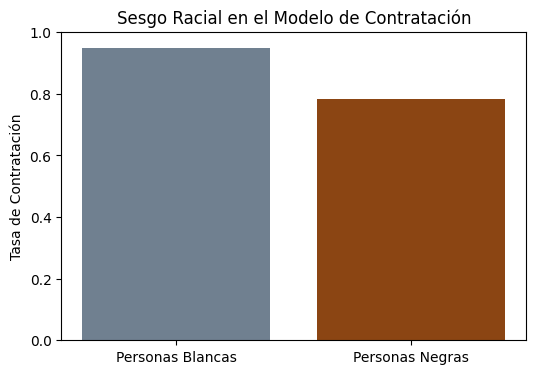

In [3]:
import matplotlib.pyplot as plt

tasa_blancos = datos_reclutamiento[datos_reclutamiento["raza"] == "blanco"]["contratado"].mean()
tasa_negros = datos_reclutamiento[datos_reclutamiento["raza"] == "negro"]["contratado"].mean()

grupos_raza = ["Personas Blancas", "Personas Negras"]
tasas_raza = [tasa_blancos, tasa_negros]

plt.figure(figsize=(6, 4))
plt.bar(grupos_raza, tasas_raza, color=["slategray", "saddlebrown"])
plt.ylabel("Tasa de Contratación")
plt.title("Sesgo Racial en el Modelo de Contratación")
plt.ylim(0, 1)
plt.show()

In [5]:
!pip install fairlearn

In [6]:
from fairlearn.metrics import MetricFrame, selection_rate

etiquetas_reales = datos_reclutamiento["contratado"]
predicciones_modelo = datos_reclutamiento["contratado"]
grupo_sensible_genero = datos_reclutamiento["genero"]

marco_metidas = MetricFrame(
    metrics=selection_rate,
    y_true=etiquetas_reales,
    y_pred=predicciones_modelo,
    sensitive_features=grupo_sensible_genero
)

print(marco_metidas.by_group)
print("\nDisparidad Demográfica de Género:", marco_metidas.difference())

genero
hombre    0.977162
mujer     0.770026
Name: selection_rate, dtype: float64

Disparidad Demográfica de Género: 0.20713566102237901


In [7]:
import pandas as pd

submuestra_hombres = datos_reclutamiento[datos_reclutamiento["genero"] == "hombre"]
submuestra_mujeres = datos_reclutamiento[datos_reclutamiento["genero"] == "mujer"]

minimo_filas = min(len(submuestra_hombres), len(submuestra_mujeres))

hombres_balanceados = submuestra_hombres.sample(n=minimo_filas, random_state=42)
mujeres_balanceadas = submuestra_mujeres.sample(n=minimo_filas, random_state=42)

datos_mitigados = pd.concat([hombres_balanceados, mujeres_balanceadas])

tasa_hombres_justa = datos_mitigados[datos_mitigados["genero"] == "hombre"]["contratado"].mean()
tasa_mujeres_justa = datos_mitigados[datos_mitigados["genero"] == "mujer"]["contratado"].mean()

print(f"Tasa Hombres (Mitigado): {tasa_hombres_justa:.2f}")
print(f"Tasa Mujeres (Mitigado): {tasa_mujeres_justa:.2f}")

Tasa Hombres (Mitigado): 0.97
Tasa Mujeres (Mitigado): 0.77


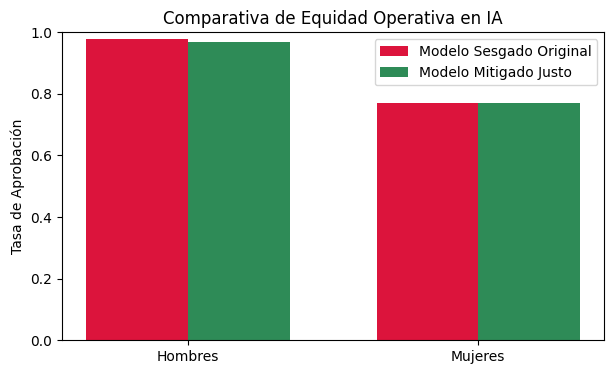

In [8]:
import matplotlib.pyplot as plt
import numpy as np

grupos_poblacion = ["Hombres", "Mujeres"]
tasas_originales = [tasa_hombres, tasa_mujeres]
tasas_corregidas = [tasa_hombres_justa, tasa_mujeres_justa]

posicion_eje = np.arange(len(grupos_poblacion))
ancho_barra = 0.35

plt.figure(figsize=(7, 4))
plt.bar(posicion_eje - ancho_barra/2, tasas_originales, ancho_barra, label="Modelo Sesgado Original", color="crimson")
plt.bar(posicion_eje + ancho_barra/2, tasas_corregidas, ancho_barra, label="Modelo Mitigado Justo", color="seagreen")

plt.ylabel("Tasa de Aprobación")
plt.title("Comparativa de Equidad Operativa en IA")
plt.xticks(posicion_eje, grupos_poblacion)
plt.ylim(0, 1)
plt.legend()
plt.show()